# Marketing & Sales Prediction – Regression Analysis

## Objective
Build and interpret regression models to predict **Sales** from marketing spends, discounts, traffic, and customer/product attributes.

This notebook is split into two parts:

- **Part 1: Linear Regression**  
  Data cleaning → EDA → encoding → baseline Linear Regression → assumption checks

- **Part 2: Regularized Regression**  
  Ridge / Lasso / ElasticNet → cross-validated tuning → coefficient inspection → final model selection

## Dataset overview
The dataset contains **2500 rows** and **10 columns**. Target variable: **Sales**.

| Column | Type (expected) | What it represents |
|---|---|---|
| TV_Ad_Spend | Numeric | TV advertising spend |
| Social_Media_Spend | Numeric | Social media spend |
| Discount_Offers | Numeric (discrete) | Discount level / offer value |
| Search_Engine_Marketing_Spend | Numeric | Search engine marketing spend |
| Product_Category | Categorical | Product category |
| Region | Categorical | Region |
| Customer_Segment | Categorical | Customer segment |
| Website_Traffic | Numeric | Website traffic |
| Conversion_Rate | Numeric | Conversion rate |
| Sales | Numeric (target) | Sales / revenue outcome |


# Part 1 – Linear Regression

In Part 1, we clean the dataset, explore it, build a baseline Linear Regression model, and check key regression assumptions.

### Step 0: Import libraries

We will use **pandas/numpy** for data handling and **matplotlib/seaborn** for charts. For modeling we will use **statsmodels** (for OLS summary) and **scikit-learn** (for training and evaluation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Setup (reproducibility)

Some missing values are filled using random sampling. We set a seed so that results stay reproducible when re-running the notebook.

In [2]:
np.random.seed(57)  # keep random fills reproducible

### Step 1: Load the dataset

We start by reading the CSV file and quickly looking at the first few rows to understand the columns and the target (`Sales`).

**Note:** Keep `market_sales.csv` in the same folder as this notebook (or update the path in the code cell).

In [3]:
# Read the dataset
df = pd.read_csv(r"C:\Users\riaka\Downloads\market_sales - LMS.csv")
# Display top 5 rows
df.head()

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
0,22483.0,17282.0,30.0,10516,Electronics,East,Budget,1000,2.11,96119
1,19308.0,18872.0,5.0,10413,Home Appliances,North,Budget,1000,2.15,82430
2,23238.0,13674.0,15.0,5715,Home Appliances,East,Mid-tier,1000,3.50,115771
3,27615.0,12551.0,20.0,10844,FMCG,South,Mid-tier,1825,2.14,83833
4,18829.0,10659.0,15.0,14564,Sports,East,Mid-tier,1000,2.55,103896


In [4]:
# check shape of the dataframe
df.shape  # (rows = 2500, cols = 10)

(2500, 10)

### Step 2: Data quality checks (missing values)

Before any modeling, we check whether any columns contain missing values and how large the missing percentage is. This helps us decide an appropriate handling strategy (mean/mode/random sampling, etc.).

In [5]:
# Function to generate count and percentage of null values
# for each column of the dataframe df
def null_count_percent(data):
    nv = data.isnull().sum()   # nv = null_value
    nv = nv[nv>0]
    nv_df = pd.DataFrame({'Feature':nv.index,'Count_Null':nv.values,
                         'Percent_Null':(nv.values/data.shape[0])*100})
    nv_df = nv_df.sort_values('Percent_Null',ascending=False)
    return nv_df

In [6]:
nv_df = null_count_percent(df)
nv_df

,Feature,Count_Null,Percent_Null
2,Discount_Offers,182,7.28
3,Product_Category,167,6.68
1,Social_Media_Spend,156,6.24
4,Region,127,5.08
0,TV_Ad_Spend,95,3.80


### Step 3: Duplicate check

If exact duplicate rows exist, they can bias the model by repeating the same information. We check the duplicate count first.

In [7]:
# Detect Duplicates
df.duplicated().sum()

np.int64(0)

### Step 4: Handle missing values

For this dataset:
- Numeric spend columns are filled using the **mean**.
- `Discount_Offers` is filled using **random sampling** from typical values (to keep realistic discrete values).
- `Product_Category` is filled with the **mode** (most frequent category).
- `Region` is filled using **random sampling** based on the existing region distribution.

A seed is set before random sampling so results stay reproducible in class.

In [8]:
cols = ['Social_Media_Spend','TV_Ad_Spend']
for i in cols:
    df[i] = df[i].fillna(df[i].mean())

In [9]:
np.random.seed(57)
dis_offer_fill_val = np.random.choice([10.0,15.0],size=182,p=[0.5,0.5])
len(dis_offer_fill_val)

182

In [10]:
dis_offer_nullval_index = df[df['Discount_Offers'].isnull()].index
len(dis_offer_nullval_index)

182

In [11]:
df.loc[dis_offer_nullval_index,'Discount_Offers'] = dis_offer_fill_val

In [12]:
df.isnull().sum()

TV_Ad_Spend                        0
Social_Media_Spend                 0
Discount_Offers                    0
Search_Engine_Marketing_Spend      0
Product_Category                 167
Region                           127
Customer_Segment                   0
Website_Traffic                    0
Conversion_Rate                    0
Sales                              0
dtype: int64

In [13]:
df['Product_Category'] = df['Product_Category'].fillna(df['Product_Category'].mode()[0])

In [14]:
region = df['Region'].value_counts(normalize=True)
print(region)
region_fill_val = np.random.choice(region.index,size=127,p=region.values)
len(region_fill_val)

Region
East     0.256216
West     0.252002
North    0.248630
South    0.243152
Name: proportion, dtype: float64


127

In [15]:
region_nullval_index = df[df['Region'].isnull()].index
len(region_nullval_index)

127

In [16]:
df.loc[region_nullval_index,'Region'] = region_fill_val

In [17]:
nv_df = null_count_percent(df)
nv_df

,Feature,Count_Null,Percent_Null


### Step 5: Check data types

We confirm which columns are numeric vs categorical. This also helps us decide encoding and scaling later.

In [18]:
df.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                  float64
Search_Engine_Marketing_Spend      int64
Product_Category                  object
Region                            object
Customer_Segment                  object
Website_Traffic                    int64
Conversion_Rate                  float64
Sales                              int64
dtype: object

### Step 6: Summary statistics (sanity check)

We review descriptive statistics to spot unusual ranges or values. This is a quick way to detect potential data issues early.

### Step 7: Save a cleaned copy

After cleaning, we save the dataset so the same cleaned version can be reused later (and results are consistent).

In [19]:
df.to_csv('market_sales_nv_cleaned.csv',index=False)

## Exploratory Data Analysis (EDA)

EDA helps us understand:
- Distribution of categorical and numeric features
- Relationships between features and the target (`Sales`)
- Potential multicollinearity (features moving together)

These insights guide modeling choices and interpretation.

In [20]:
cat_cols = df.dtypes[df.dtypes=='object'].index
num_cols = df.dtypes[df.dtypes!='object'].index
print(cat_cols)
print(num_cols)

Index(['Product_Category', 'Region', 'Customer_Segment'], dtype='object')
Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Discount_Offers',
       'Search_Engine_Marketing_Spend', 'Website_Traffic', 'Conversion_Rate',
       'Sales'],
      dtype='object')


### Step 8: Univariate analysis (categorical)

Countplots show how frequently each category appears. If one category dominates, it can influence the model.

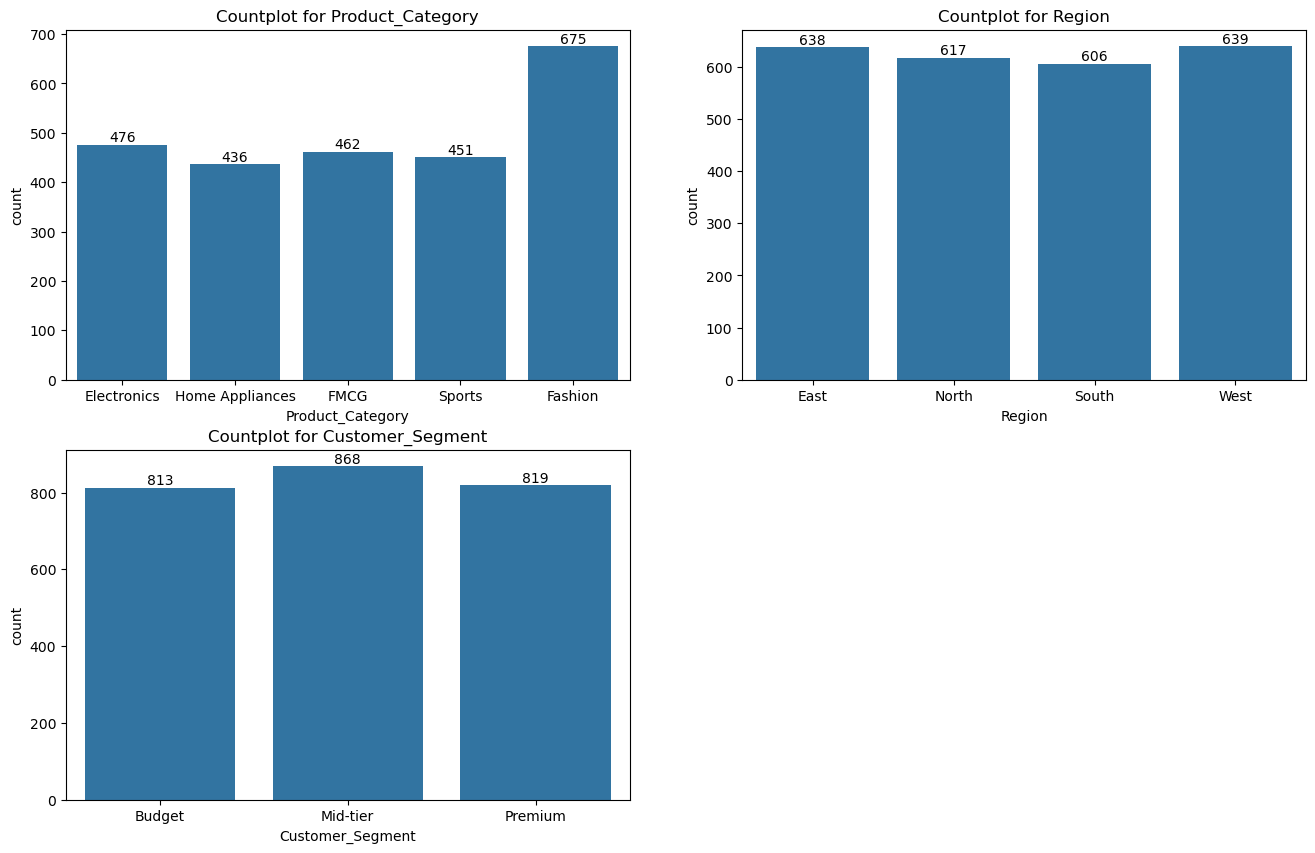

In [21]:
cols = cat_cols

plt.figure(figsize=(16,10))
for i in range(len(cols)):
    plt.subplot(2,2,i+1)
    ax= sns.countplot(x=df[cols[i]])
    ax.bar_label(ax.containers[0])
    plt.title(f'Countplot for {cols[i]}')
plt.show()

### Step 12: Bivariate analysis (categorical vs target)

We compare **average Sales** across categories to see which groups tend to perform better or worse.

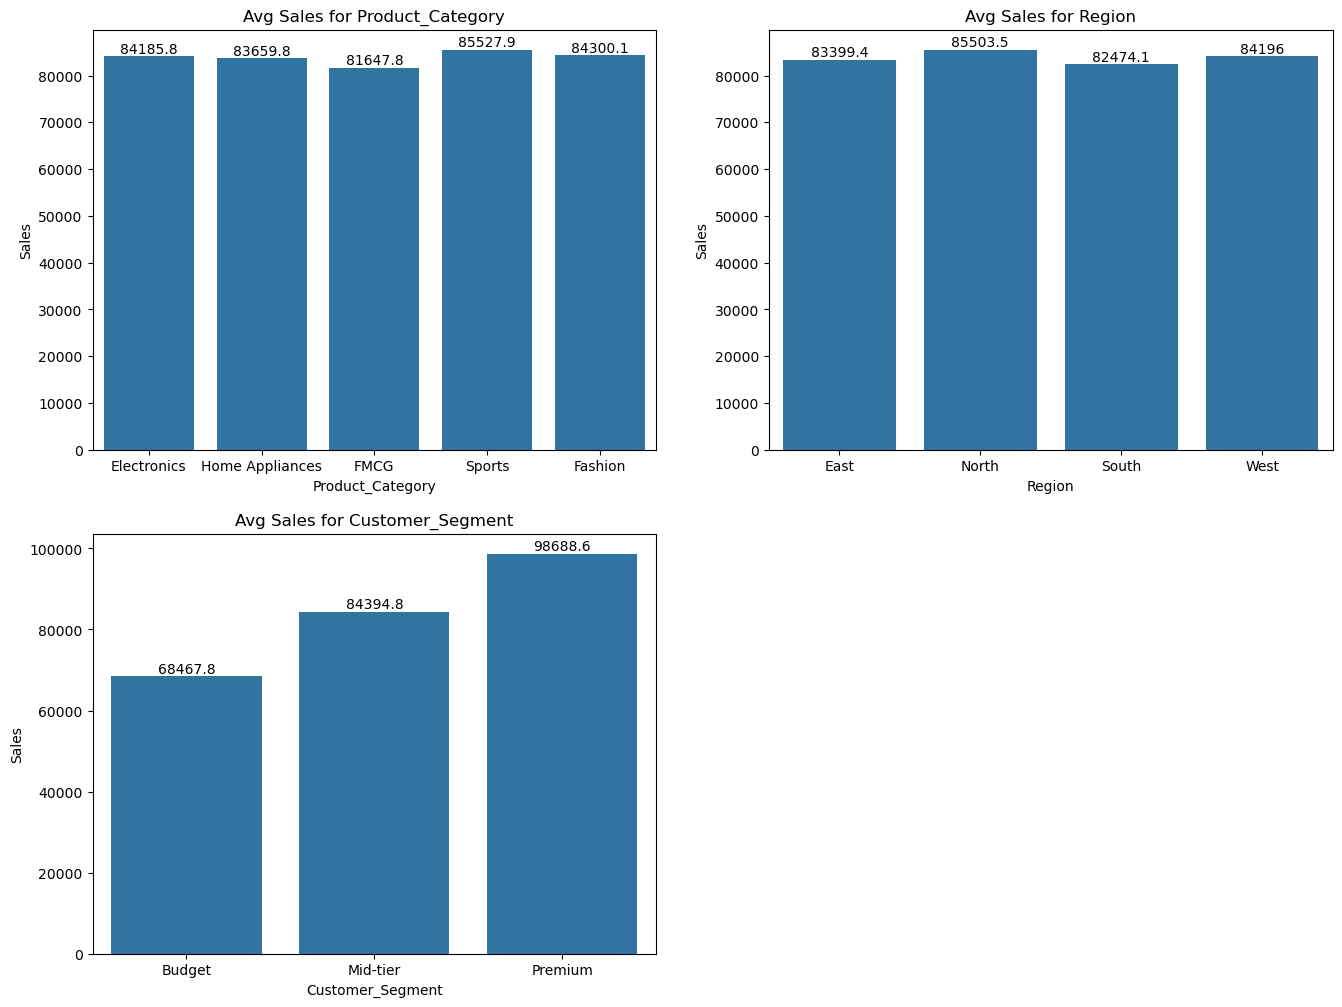

In [22]:
cols = cat_cols

plt.figure(figsize=(16,12))
for i in range(len(cols)):
    plt.subplot(2,2,i+1)
    ax= sns.barplot(x=df[cols[i]],y=df['Sales'],errorbar=('ci',0))
    ax.bar_label(ax.containers[0])
    plt.title(f'Avg Sales for {cols[i]}')
plt.show()

### Step 13: Bivariate analysis (numerical vs target)

Scatterplots help us check whether a roughly linear relationship exists between numeric inputs and `Sales`.

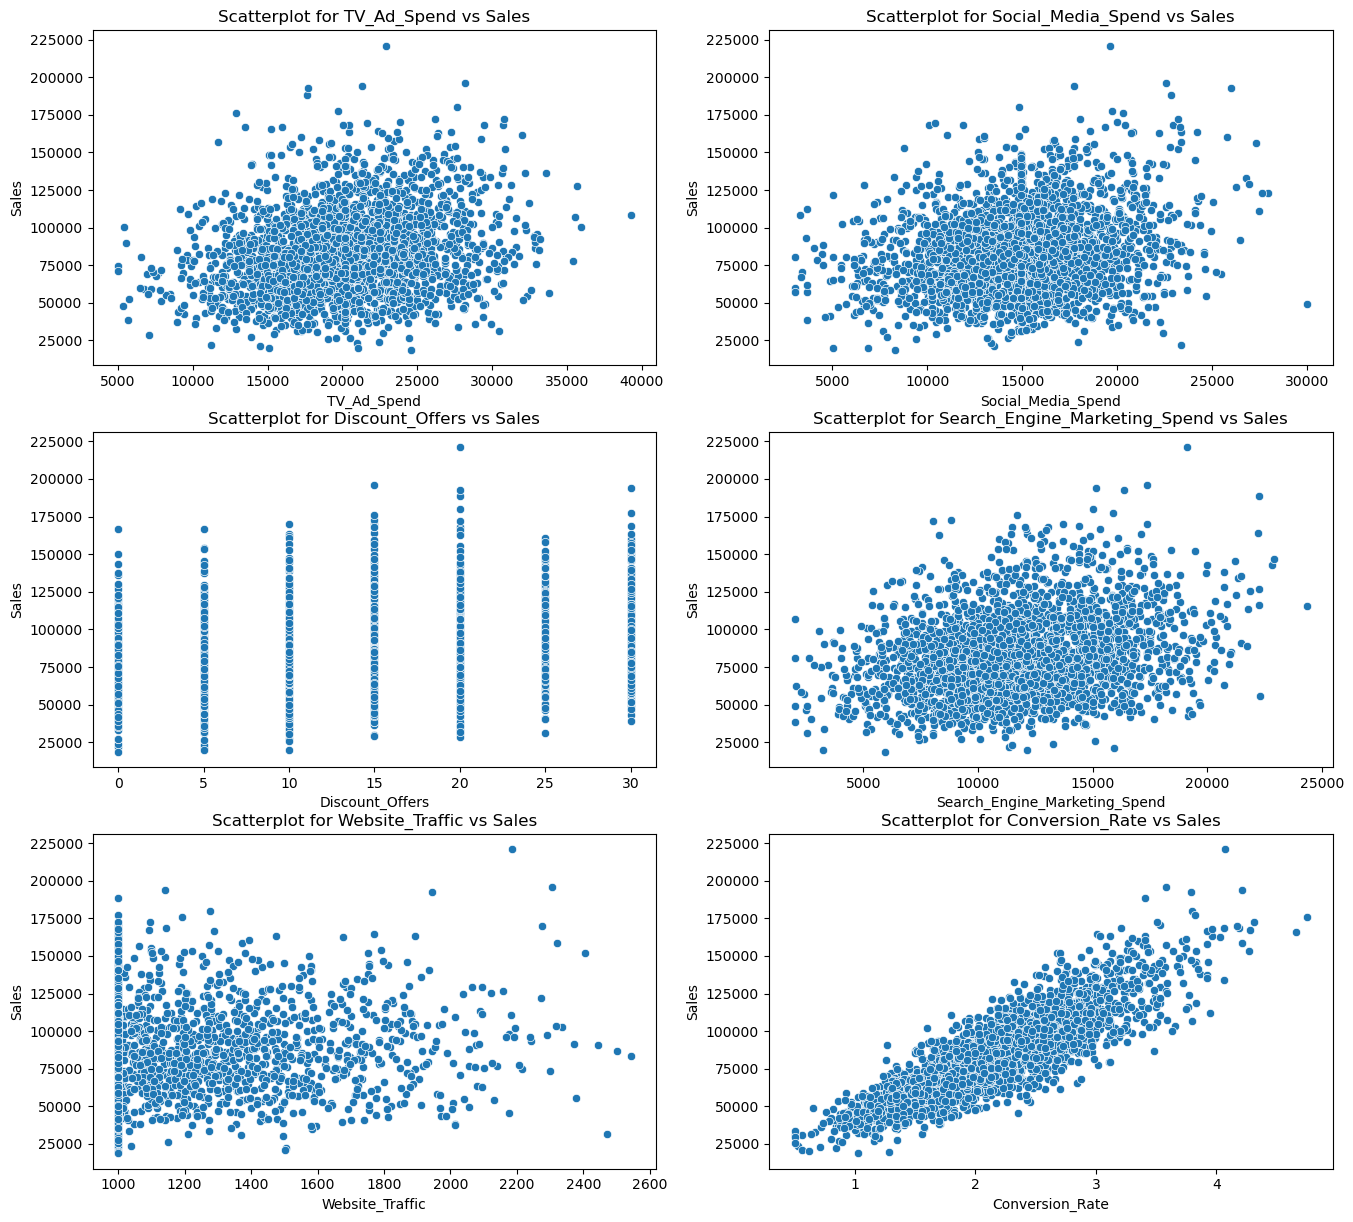

In [23]:
cols = num_cols[:-1]

plt.figure(figsize=(16,20))
for i in range(len(cols)):
    plt.subplot(4,2,i+1)
    sns.scatterplot(x=df[cols[i]],y=df['Sales'])
    plt.title(f'Scatterplot for {cols[i]} vs Sales')
plt.show()

### Step 14: Correlation (numeric features)

A correlation heatmap gives a quick view of relationships between numeric variables. Extremely high correlations can indicate multicollinearity.

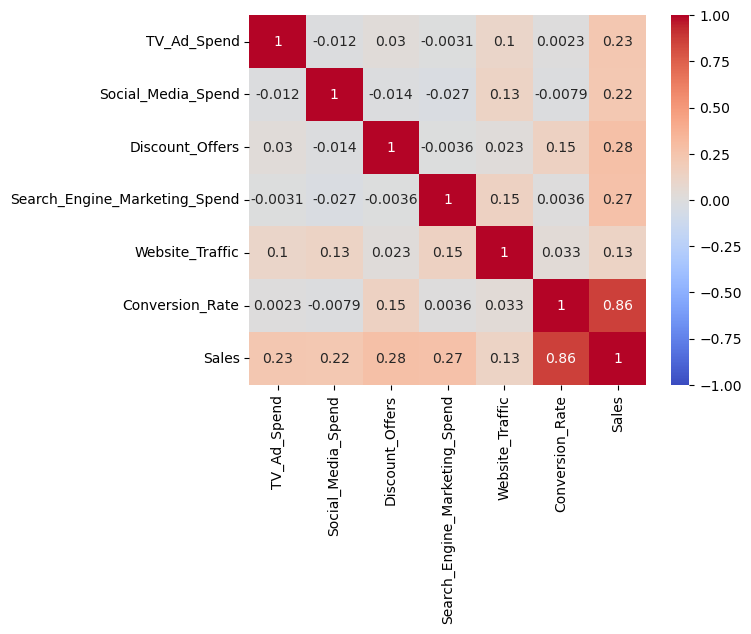

In [24]:
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True,vmin=-1,vmax=1, cmap = 'coolwarm')
plt.show()

## Feature Engineering

### Step 15: Encode categorical variables

Linear models need numeric inputs, so we convert categorical columns into dummy variables (one-hot encoding). We drop the first category to avoid redundancy.

In [25]:
df_dummies = pd.get_dummies(data=df,columns=cat_cols,drop_first=True,
                           dtype=int)
print(df_dummies.shape)
print(df_dummies.columns)

(2500, 16)
Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Discount_Offers',
       'Search_Engine_Marketing_Spend', 'Website_Traffic', 'Conversion_Rate',
       'Sales', 'Product_Category_FMCG', 'Product_Category_Fashion',
       'Product_Category_Home Appliances', 'Product_Category_Sports',
       'Region_North', 'Region_South', 'Region_West',
       'Customer_Segment_Mid-tier', 'Customer_Segment_Premium'],
      dtype='object')


### Step 16: Define features (X) and target (y)

`Sales` is our target. Everything else becomes input features.

In [26]:
x = df_dummies.drop('Sales',axis=1)
y = df_dummies['Sales']
print(x.shape)
print(y.shape)

(2500, 15)
(2500,)


## Baseline statistical model (OLS)

### Step 17: OLS regression summary (statsmodels)

An OLS summary gives:
- Coefficients + p-values (rough statistical significance)
- R² and adjusted R²
- Diagnostics that are useful for assumption checking

We use this as an interpretable baseline before moving to a train/test evaluation.

In [27]:
import statsmodels.api as sm

In [28]:
# create copies of x1 and y1 
x1 = x.copy()
y1 = y.copy()

In [29]:
x1 = sm.add_constant(x1)     # added to generate intercept
ols_m1  = sm.OLS(y1,x1).fit()  # Train the OLS Model
ols_m1.summary()              # generate OLS Summary

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.944
Model:                            OLS   Adj. R-squared:                  0.944
Method:                 Least Squares   F-statistic:                     2792.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:25:17   Log-Likelihood:                -25536.
No. Observations:                2500   AIC:                         5.110e+04
Df Residuals:                    2484   BIC:                         5.120e+04
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
====================================================================================================
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const                            -7.871e+04   1126.758    -69.857      0.000   -8.09e+04   -7.65e+04
TV_Ad_Spend                          1.3114      0.028     47.039      0.000       1.257       1.366
Social_Media_Spend                   1.7042      0.034     49.634      0.000       1.637       1.771
Discount_Offers                    498.4984     15.660     31.832      0.000     467.790     529.207
Search_Engine_Marketing_Spend        2.1428      0.038     56.972      0.000       2.069       2.217
Website_Traffic                      0.0927      0.483      0.192      0.848      -0.854       1.040
Conversion_Rate                   3.621e+04    245.045    147.782      0.000    3.57e+04    3.67e+04
Product_Category_FMCG              292.8778    434.055      0.675      0.500    -558.268    1144.024
Product_Category_Fashion          1067.4190    398.010      2.682      0.007     286.953    1847.885
Product_Category_Home Appliances   216.7703    440.233      0.492      0.622    -646.492    1080.032
Product_Category_Sports           1117.7394    436.422      2.561      0.010     261.951    1973.528
Region_North                       265.5028    375.699      0.707      0.480    -471.213    1002.219
Region_South                      -306.5086    376.562     -0.814      0.416   -1044.915     431.898
Region_West                        251.9906    371.233      0.679      0.497    -475.967     979.949
Customer_Segment_Mid-tier           43.7812    341.112      0.128      0.898    -625.112     712.675
Customer_Segment_Premium           217.8917    386.926      0.563      0.573    -540.839     976.623
==============================================================================
Omnibus:                       43.858   Durbin-Watson:                   2.004
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               85.845
Skew:                           0.028   Prob(JB):                     2.29e-19
Kurtosis:                       3.906   Cond. No.                     2.44e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.44e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Split data into train and test

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,
                                                random_state=57)
print(x_train.shape,x_test.shape)
print(y_train.shape,y_test.shape)

(1750, 15) (750, 15)
(1750,) (750,)


## Baseline ML model (Linear Regression)

### Step 18: Train/test split + scikit-learn model

We now build a baseline **Linear Regression** model using a train/test split and evaluate it with common regression metrics.

In [32]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import *

In [33]:
def eval_model(ytest,ypred):
    mae = mean_absolute_error(ytest,ypred) # compute mae between test and pred  
    mse = mean_squared_error(ytest,ypred)  # compute mse between test and pred  
    rmse = np.sqrt(mse)                    # compute rmse between test and pred                  
    r2 = r2_score(ytest,ypred)             # compute r2 score between test and pred                  
    print('MAE',mae,'MSE',mse,'RMSE',rmse)
    print('Test_R2',r2)

In [34]:
lr1 = LinearRegression()    # Create an instance of Linear Regreisson
lr1.fit(x_train,y_train)    # Train model on x_train and y_train

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
ypred_lr1 = lr1.predict(x_test)  
eval_model(y_test,ypred_lr1)

MAE 5190.425102132411 MSE 45677791.692546114 RMSE 6758.534729698895
Test_R2 0.9410607476284393


### Step 18.5: Quick overfitting check

Train vs test R² gives a simple view of whether the model generalizes well.

In [36]:
print('Train Score',lr1.score(x_train,y_train))   # Train R2_Score
print('Test Score',lr1.score(x_test,y_test))      # Test R2_Score

Train Score 0.9449801281815277
Test Score 0.9410607476284393


### Step 18.6: Coefficients and intercept

Coefficients show how much `Sales` changes when the feature increases by 1 unit (keeping other features fixed).

In [37]:
m_lr = lr1.coef_
c_lr = lr1.intercept_
print('Coef',m_lr)
print('Intercept',c_lr)

Coef [ 1.34866858e+00  1.70573931e+00  5.05708795e+02  2.17887221e+00
 -5.36475570e-01  3.60864877e+04  2.92881829e+02  9.88685200e+02
  4.93432269e+02  8.70611723e+02  1.60122703e+02 -6.16557909e+02
  1.68466166e+02  4.25240143e+01  1.92004351e+01]
Intercept -78740.8519578073


In [38]:
feat_coef = pd.DataFrame({'Features':x_train.columns,'Coef':m_lr})
feat_coef

,Features,Coef
0,TV_Ad_Spend,1.348669
1,Social_Media_Spend,1.705739
2,Discount_Offers,505.708795
3,Search_Engine_Marketing_Spend,2.178872
4,Website_Traffic,-0.536476
5,Conversion_Rate,36086.487741
6,Product_Category_FMCG,292.881829
7,Product_Category_Fashion,988.685200
8,Product_Category_Home Appliances,493.432269
9,Product_Category_Sports,870.611723


#### Compare/Observe Test Sales and Predicted Sales

In [39]:
result = pd.DataFrame({'Test':y_test,'Predictions':ypred_lr1})
result.head(10)

,Test,Predictions
696,73443,71242.321743
1540,121021,114341.623952
771,104381,97389.848405
2216,83659,77959.705252
118,83638,79845.095229
2217,98919,93679.675049
2211,86031,88340.491652
1409,86710,87432.281242
1845,78405,88836.149411
678,143806,133624.716224


## Regression assumption checks (Part 1)

A linear regression model is most reliable when these conditions are reasonably met:

1. **Linearity**: the relationship between inputs and *Sales* is approximately linear  
2. **No strong multicollinearity**: features are not near-duplicates of each other  
3. **Homoscedasticity**: residual spread is roughly constant across predictions (no “funnel shape”)  
4. **Residuals are roughly normal**: mainly important for interpretation / inference (p-values, confidence intervals)

We will check these using simple plots + a few standard diagnostics.


### 1) Linearity check (quick visual)

We look at a few key numeric features and see whether the trend with *Sales* is roughly straight-line.
This is a **quick** check (real-world data is rarely perfectly linear).


In [40]:
 # Pick the top 3 numeric features most correlated with Sales (simple way to choose what to plot)/
numeric_cols = ['TV_Ad_Spend','Social_Media_Spend','Discount_Offers',
                'Search_Engine_Marketing_Spend','Website_Traffic','Conversion_Rate']

corr_with_sales = df[numeric_cols + ['Sales']].corr()['Sales'].drop('Sales').sort_values(ascending=False)
corr_with_sales


Conversion_Rate                  0.860978
Discount_Offers                  0.279514
Search_Engine_Marketing_Spend    0.270256
TV_Ad_Spend                      0.228740
Social_Media_Spend               0.220002
Website_Traffic                  0.127254
Name: Sales, dtype: float64

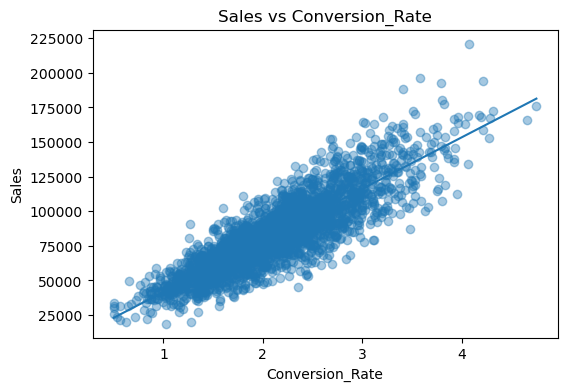

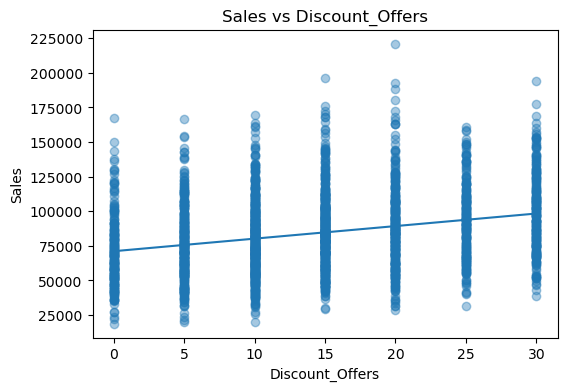

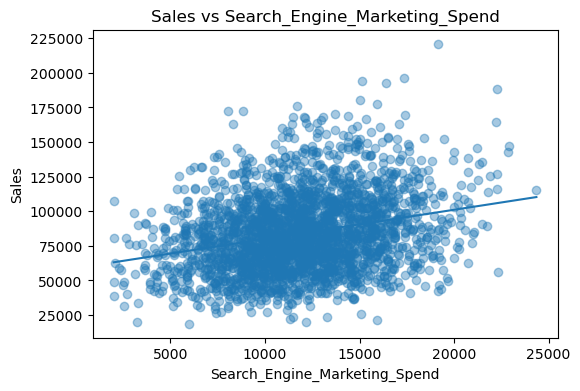

In [41]:
top_features = list(corr_with_sales.index[:3])

for col in top_features:
    plt.figure(figsize=(6,4))
    plt.scatter(df[col], df['Sales'], alpha=0.4)

    # Simple line of best fit (visual guide)
    m, b = np.polyfit(df[col], df['Sales'], 1)
    x_line = np.linspace(df[col].min(), df[col].max(), 100)
    plt.plot(x_line, m*x_line + b)

    plt.title(f"Sales vs {col}")
    plt.xlabel(col)
    plt.ylabel("Sales")
    plt.show()

### 2) Multicollinearity check (VIF)

A common rule of thumb:
- VIF around **1–5**: usually acceptable  
- VIF **> 10**: strong multicollinearity concern

We compute VIF on the training features (after encoding).


In [42]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = x_train.copy()
X_vif_const = sm.add_constant(X_vif)
# X_vif_const = X_vif
vif_df = pd.DataFrame()
vif_df['Feature'] = X_vif_const.columns
vif_df['VIF'] = [variance_inflation_factor(X_vif_const.values, i) for i in range(X_vif_const.shape[1])]

# Show the top VIF values (higher first)
vif_df.sort_values('VIF', ascending=False).head(15)


,Feature,VIF
0,const,70.625425
15,Customer_Segment_Premium,1.883434
8,Product_Category_Fashion,1.740383
10,Product_Category_Sports,1.597900
7,Product_Category_FMCG,1.594919
9,Product_Category_Home Appliances,1.588774
13,Region_West,1.528956
11,Region_North,1.517744
12,Region_South,1.503916
14,Customer_Segment_Mid-tier,1.499511


### 3) Homoscedasticity check (residuals vs predicted)

We plot residuals against predicted values. Ideally, residuals are scattered randomly around 0 with a roughly constant spread.


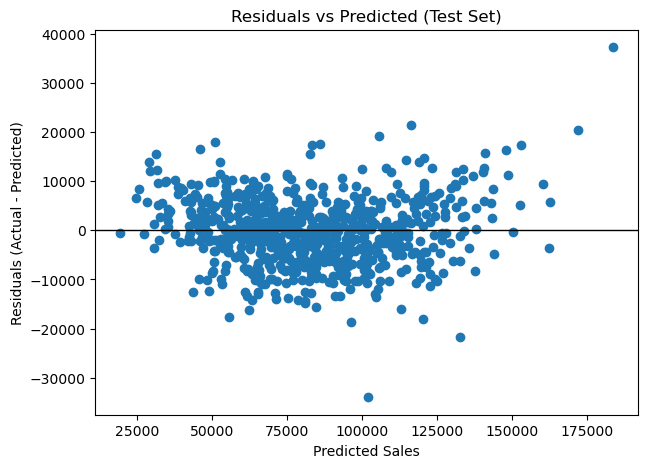

In [43]:
# Residuals on the test set from the baseline sklearn LinearRegression model
residuals = y_test - ypred_lr1

plt.figure(figsize=(7,5))
plt.scatter(ypred_lr1, residuals)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residuals vs Predicted (Test Set)')
plt.xlabel('Predicted Sales')
plt.ylabel('Residuals (Actual - Predicted)')
plt.show()


In [44]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

# Fit OLS on training data for diagnostics
X_train_sm = sm.add_constant(x_train)
ols_train = sm.OLS(y_train, X_train_sm).fit()

# Breusch–Pagan test
bp_stat, bp_pvalue, f_stat, f_pvalue = het_breuschpagan(ols_train.resid, ols_train.model.exog)
print("Breusch–Pagan p-value:", bp_pvalue)

# Durbin–Watson (extra diagnostic)
dw = durbin_watson(ols_train.resid)
print("Durbin–Watson:", dw)


Breusch–Pagan p-value: 0.0991139828736881
Durbin–Watson: 1.9886709182436952


### 4) Normality of residuals (visual)

Residual normality is mainly used for *inference* (p-values, confidence intervals).  
For prediction, small deviations are usually acceptable, but large deviations can still indicate missing patterns.


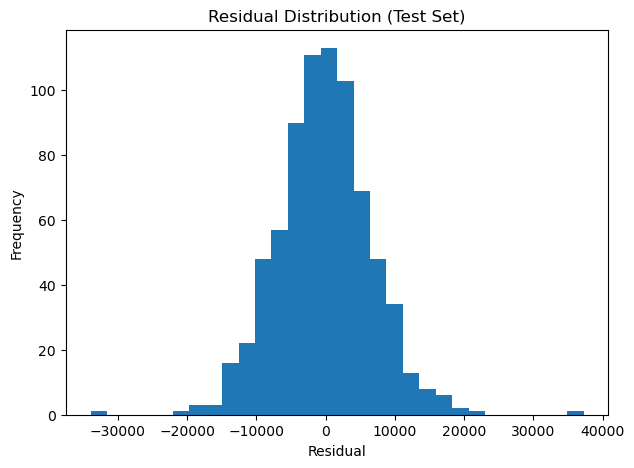

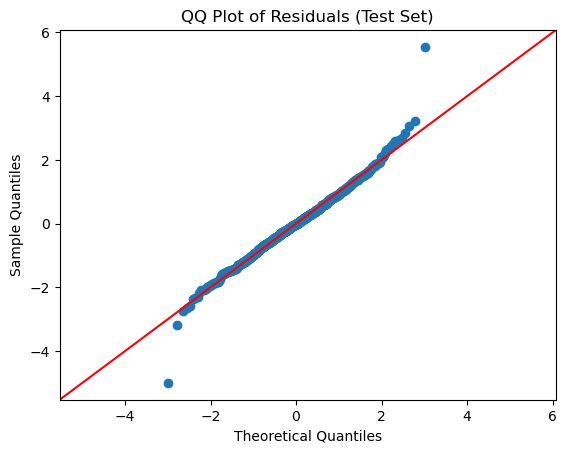

In [45]:
plt.figure(figsize=(7,5))
plt.hist(residuals, bins=30)
plt.title('Residual Distribution (Test Set)')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()

import scipy.stats as stats
sm.qqplot(residuals, line='45', fit=True)
plt.title('QQ Plot of Residuals (Test Set)')
plt.show()


---

# Part 2 – Regularized Regression

In Part 2, we use the **same dataset** and the **same train/test split** from Part 1.

Goal:
- Train **Ridge**, **Lasso**, and **ElasticNet**
- Compare them with the baseline Linear Regression model
- Then use **K-Fold cross-validation** to tune hyperparameters (alpha / l1_ratio)
- Inspect coefficients (shrinkage vs feature removal)
- Select **one final model** and justify the choice clearly


## Step 1: Why scaling is used here

Regularization penalties (Ridge/Lasso/ElasticNet) are sensitive to the scale of features.  
So we standardize the input features so that each column is on a comparable scale.


In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [47]:
# Scale features (fit scaler only on training set)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Convert back to DataFrame to keep column names (helps interpretation)
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns, index=x_test.index)


## Step 2: Train Ridge, Lasso, ElasticNet (no cross-validation yet)

First, we train each model **once** using a reasonable starting configuration.
This gives a simple, direct comparison against the baseline model from Part 1.

> Important: These are **not tuned** yet. The goal here is to understand how each model behaves before introducing K-Fold.


In [48]:
# Helper to store metrics in a clean table
def get_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

results_initial = []

In [49]:
pred_baseline = lr1.predict(x_test)
baseline_metrics = get_metrics(y_test, pred_baseline)
baseline_metrics['Model'] = 'Baseline LinearRegression (Part 1)'
results_initial.append(baseline_metrics)

### Ridge (L2)

In [50]:
ridge_basic = Ridge(alpha=1.0)
ridge_basic.fit(x_train_scaled, y_train)
pred_ridge = ridge_basic.predict(x_test_scaled)
m_ridge = get_metrics(y_test, pred_ridge)
m_ridge['Model'] = 'Ridge (alpha=1.0)'
results_initial.append(m_ridge)

### Lasso (L1) - alpha is kept small to avoid over-shrinking early

In [51]:
lasso_basic = Lasso(alpha=0.01, max_iter=10000)
lasso_basic.fit(x_train_scaled, y_train)
pred_lasso = lasso_basic.predict(x_test_scaled)
m_lasso = get_metrics(y_test, pred_lasso)
m_lasso['Model'] = 'Lasso (alpha=0.01)'
results_initial.append(m_lasso)

### ElasticNet (L1 + L2)

In [52]:
enet_basic = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)
enet_basic.fit(x_train_scaled, y_train)
pred_enet = enet_basic.predict(x_test_scaled)
m_enet = get_metrics(y_test, pred_enet)
m_enet['Model'] = 'ElasticNet (alpha=0.01, l1_ratio=0.5)'
results_initial.append(m_enet)

In [53]:
results_initial_df = pd.DataFrame(results_initial).sort_values('RMSE')
results_initial_df

,MAE,RMSE,R2,Model
1,5189.508289,6758.403937,0.941063,Ridge (alpha=1.0)
2,5190.424506,6758.532688,0.941061,Lasso (alpha=0.01)
0,5190.425102,6758.534730,0.941061,Baseline LinearRegression (Part 1)
3,5183.915855,6758.832274,0.941056,"ElasticNet (alpha=0.01, l1_ratio=0.5)"


## Step 3: K-Fold cross-validation (concept)

Train/test split gives only **one** view of performance (depends on the split).  
K-Fold cross-validation gives a more reliable estimate by training and validating multiple times on different folds.

We will use:
- **Mean RMSE across folds** (lower is better)
- **Std RMSE across folds** (lower = more stable)
- Mean and Std of **R²** (optional supporting metric)


In [54]:
def kfold_score(model_class, model_params, X, y, k=5, random_state=57):
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    rmse_scores = []
    r2_scores = []

    for tr_idx, val_idx in kf.split(X):
        X_tr = X.iloc[tr_idx]
        X_val = X.iloc[val_idx]
        y_tr = y.iloc[tr_idx]
        y_val = y.iloc[val_idx]

        model = model_class(**model_params)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)

        rmse = np.sqrt(mean_squared_error(y_val, pred))
        r2 = r2_score(y_val, pred)

        rmse_scores.append(rmse)
        r2_scores.append(r2)

    return {
        'RMSE_Mean': np.mean(rmse_scores),
        'RMSE_Std': np.std(rmse_scores),
        'R2_Mean': np.mean(r2_scores),
        'R2_Std': np.std(r2_scores)
    }


## Step 4: Tune Ridge (alpha) with K-Fold

Ridge shrinks coefficients but does not set them exactly to 0.  
We try multiple alpha values and choose the one with the lowest mean RMSE.


In [55]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_cv_results = []
for a in ridge_alphas:
    res = kfold_score(Ridge, {'alpha': a}, x_train_scaled, y_train)
    res['Model'] = 'Ridge'
    res['alpha'] = a
    ridge_cv_results.append(res)

ridge_cv_df = pd.DataFrame(ridge_cv_results).sort_values('RMSE_Mean')
ridge_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
1,6597.876201,207.034527,0.943627,0.006010,Ridge,0.10
0,6597.877466,206.959404,0.943627,0.006009,Ridge,0.01
2,6597.896038,207.781658,0.943627,0.006017,Ridge,1.00
3,6601.256952,214.853317,0.943566,0.006088,Ridge,10.00
4,6878.020048,255.677826,0.938750,0.006654,Ridge,100.00
5,12748.194185,478.422468,0.790649,0.008089,Ridge,1000.00


## Step 5: Tune Lasso (alpha) with K-Fold

Lasso can push weak feature coefficients exactly to **0**, which behaves like feature selection.  
We try a few alpha values and choose the best by mean RMSE.


In [56]:
lasso_alphas = [0.0001, 0.001, 0.01, 0.1, 1]

lasso_cv_results = []
for a in lasso_alphas:
    res = kfold_score(Lasso, {'alpha': a, 'max_iter': 10000}, x_train_scaled, y_train)
    res['Model'] = 'Lasso'
    res['alpha'] = a
    lasso_cv_results.append(res)

lasso_cv_df = pd.DataFrame(lasso_cv_results).sort_values('RMSE_Mean')
lasso_cv_df

,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha
4,6597.610941,206.990721,0.943632,0.006008,Lasso,1.0000
3,6597.850806,206.955130,0.943628,0.006009,Lasso,0.1000
2,6597.874950,206.951447,0.943627,0.006009,Lasso,0.0100
1,6597.877374,206.951093,0.943627,0.006009,Lasso,0.0010
0,6597.877616,206.951056,0.943627,0.006009,Lasso,0.0001


## Step 6: Tune ElasticNet (alpha and l1_ratio) with K-Fold

ElasticNet combines Ridge and Lasso:
- `alpha`: overall penalty strength
- `l1_ratio`: mixing ratio (0 = Ridge-like, 1 = Lasso-like)

We try a small grid and choose the best by mean RMSE.


In [57]:
enet_alphas = [0.001, 0.01, 0.1, 1, 10]
enet_l1_ratios = [0.1, 0.5, 0.9]

enet_cv_results = []
for a in enet_alphas:
    for l1 in enet_l1_ratios:
        res = kfold_score(ElasticNet, {'alpha': a, 'l1_ratio': l1, 'max_iter': 10000}, x_train_scaled, y_train)
        res['Model'] = 'ElasticNet'
        res['alpha'] = a
        res['l1_ratio'] = l1
        enet_cv_results.append(res)

enet_cv_df = pd.DataFrame(enet_cv_results).sort_values('RMSE_Mean')
enet_cv_df


,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std,Model,alpha,l1_ratio
2,6597.875588,207.067928,0.943627,0.006010,ElasticNet,0.001,0.9
1,6597.882743,207.533462,0.943627,0.006015,ElasticNet,0.001,0.5
0,6597.912703,207.996117,0.943626,0.006019,ElasticNet,0.001,0.1
5,6597.921434,208.111681,0.943626,0.006020,ElasticNet,0.010,0.9
4,6599.508669,212.575607,0.943597,0.006064,ElasticNet,0.010,0.5
3,6603.262556,216.765446,0.943531,0.006108,ElasticNet,0.010,0.1
8,6604.516261,217.777146,0.943510,0.006118,ElasticNet,0.100,0.9
7,6745.673917,246.777886,0.941073,0.006493,ElasticNet,0.100,0.5
6,7015.366074,261.118357,0.936295,0.006774,ElasticNet,0.100,0.1
11,7096.527346,263.471934,0.934822,0.006831,ElasticNet,1.000,0.9


## Step 7: Compare the best configuration from each model

We pick the best row (lowest mean RMSE) from each model type and compare them.


In [58]:
best_ridge = ridge_cv_df.iloc[0]
best_lasso = lasso_cv_df.iloc[0]
best_enet = enet_cv_df.iloc[0]

compare_cv = pd.DataFrame([best_ridge, best_lasso, best_enet])
# print(best_ridge)
# print(best_lasso)
# print(best_enet)
compare_cv[['Model','alpha','l1_ratio','RMSE_Mean','RMSE_Std','R2_Mean','R2_Std']]

,Model,alpha,l1_ratio,RMSE_Mean,RMSE_Std,R2_Mean,R2_Std
1,Ridge,0.100,NaN,6597.876201,207.034527,0.943627,0.006010
4,Lasso,1.000,NaN,6597.610941,206.990721,0.943632,0.006008
2,ElasticNet,0.001,0.9,6597.875588,207.067928,0.943627,0.006010


Now we train the **tuned** versions of Ridge, Lasso, and ElasticNet on the full training data and evaluate them on the test set.


In [59]:
results_list = []

# Baseline again (for easy comparison in one table)
results_list.append({
    'Model': 'Baseline LinearRegression (Part 1)',
    **get_metrics(y_test, lr1.predict(x_test))
})

# Tuned regularized models (scaled features)
ridge_final = Ridge(alpha=float(best_ridge['alpha']))
lasso_final = Lasso(alpha=float(best_lasso['alpha']), max_iter=10000)
enet_final = ElasticNet(alpha=float(best_enet['alpha']), l1_ratio=float(best_enet['l1_ratio']), max_iter=10000)

for name, model in [('Ridge (tuned)', ridge_final), ('Lasso (tuned)', lasso_final), ('ElasticNet (tuned)', enet_final)]:
    model.fit(x_train_scaled, y_train)
    pred = model.predict(x_test_scaled)
    results_list.append({
        'Model': name,
        **get_metrics(y_test, pred)
    })

results_df = pd.DataFrame(results_list).sort_values('RMSE')
results_df


,Model,MAE,RMSE,R2
2,Lasso (tuned),5190.368941,6758.333030,0.941064
3,ElasticNet (tuned),5190.257845,6758.508530,0.941061
1,Ridge (tuned),5190.329470,6758.519701,0.941061
0,Baseline LinearRegression (Part 1),5190.425102,6758.534730,0.941061


## Step 8: Coefficient inspection (shrinkage vs feature removal)

To compare coefficient behavior, we look at coefficients on **scaled features**.

- Ridge: shrinks coefficients but usually keeps all features  
- Lasso: may set some coefficients exactly to 0 (feature removal)  
- ElasticNet: can do both shrinkage and selective removal


In [60]:
# Fit a plain LinearRegression on scaled features (for coefficient comparison only)
lr_scaled = LinearRegression()
lr_scaled.fit(x_train_scaled, y_train)

# Ensure tuned models are fitted (already done above, but safe to repeat)
ridge_final.fit(x_train_scaled, y_train)
lasso_final.fit(x_train_scaled, y_train)
enet_final.fit(x_train_scaled, y_train)

coef_df = pd.DataFrame({
    'Feature': x_train.columns,
    'LinearReg_Scaled': lr_scaled.coef_,
    'Ridge_Coef': ridge_final.coef_,
    'Lasso_Coef': lasso_final.coef_,
    'ElasticNet_Coef': enet_final.coef_
})

# Count near-zero coefficients (feature removal)
zero_lasso = (coef_df['Lasso_Coef'].abs() < 1e-8).sum()
zero_enet = (coef_df['ElasticNet_Coef'].abs() < 1e-8).sum()
print("Number of near-zero coefficients (Lasso):", zero_lasso)
print("Number of near-zero coefficients (ElasticNet):", zero_enet)

# Show the strongest features for each model (by absolute coefficient)
coef_df['Abs_LR'] = coef_df['LinearReg_Scaled'].abs()
coef_df['Abs_Ridge'] = coef_df['Ridge_Coef'].abs()
coef_df['Abs_Lasso'] = coef_df['Lasso_Coef'].abs()
coef_df['Abs_Enet'] = coef_df['ElasticNet_Coef'].abs()

coef_df.sort_values('Abs_Ridge', ascending=False).head(12)


Number of near-zero coefficients (Lasso): 0
Number of near-zero coefficients (ElasticNet): 0


,Feature,LinearReg_Scaled,Ridge_Coef,Lasso_Coef,ElasticNet_Coef,Abs_LR,Abs_Ridge,Abs_Lasso,Abs_Enet
5,Conversion_Rate,23367.910113,23366.062971,23367.842749,23364.677846,23367.910113,23366.062971,23367.842749,23364.677846
3,Search_Engine_Marketing_Spend,7729.408575,7728.933722,7728.217043,7728.576549,7729.408575,7728.933722,7728.217043,7728.576549
1,Social_Media_Spend,6752.409317,6751.984606,6751.230016,6751.665045,6752.409317,6751.984606,6751.230016,6751.665045
0,TV_Ad_Spend,6508.039962,6507.656068,6506.968219,6507.367215,6508.039962,6507.656068,6506.968219,6507.367215
2,Discount_Offers,4356.402476,4356.401931,4355.527037,4356.400697,4356.402476,4356.401931,4355.527037,4356.400697
7,Product_Category_Fashion,433.671185,433.568497,429.169034,433.487466,433.671185,433.568497,429.169034,433.487466
9,Product_Category_Sports,336.941956,336.868028,332.787149,336.808873,336.941956,336.868028,332.787149,336.808873
11,Region_South,-263.962036,-263.930334,-264.006395,-263.906609,263.962036,263.930334,264.006395,263.906609
8,Product_Category_Home Appliances,190.038776,189.993343,185.817844,189.955487,190.038776,189.993343,185.817844,189.955487
4,Website_Traffic,-151.839922,-151.603462,-150.345617,-151.424815,151.839922,151.603462,150.345617,151.424815


## Step 9: Select ONE final model and justify

We select a final model based on:
- Best (lowest) **CV mean RMSE**
- Good **CV stability** (lower RMSE std)
- Competitive **test performance**
- Coefficient behavior (shrinkage / feature removal) and interpretability


In [61]:
# Winner based on CV mean RMSE (lower is better)
best_candidates = {
    'Ridge': float(best_ridge['RMSE_Mean']),
    'Lasso': float(best_lasso['RMSE_Mean']),
    'ElasticNet': float(best_enet['RMSE_Mean'])
}
winner = min(best_candidates, key=best_candidates.get)
winner


'Lasso'

In [62]:
# Build a clear justification note using results we computed above

if winner == 'Ridge':
    final_model_name = f"Ridge (alpha={float(best_ridge['alpha'])})"
    final_model = ridge_final
    final_coefs = pd.Series(ridge_final.coef_, index=x_train.columns)
    final_cv_row = best_ridge
elif winner == 'Lasso':
    final_model_name = f"Lasso (alpha={float(best_lasso['alpha'])})"
    final_model = lasso_final
    final_coefs = pd.Series(lasso_final.coef_, index=x_train.columns)
    final_cv_row = best_lasso
else:
    final_model_name = f"ElasticNet (alpha={float(best_enet['alpha'])}, l1_ratio={float(best_enet['l1_ratio'])})"
    final_model = enet_final
    final_coefs = pd.Series(enet_final.coef_, index=x_train.columns)
    final_cv_row = best_enet

# Pick the test metrics row
test_row = results_df[results_df['Model'].str.contains(winner, case=False)].iloc[0]

top_features = final_coefs.abs().sort_values(ascending=False).head(5)

print("Final Model Selected:", final_model_name)
print()

print("Which model won?")
print(f"  - {final_model_name}")
print()

print("Why?")
print(f"  - Lowest mean CV RMSE among regularized models: {final_cv_row['RMSE_Mean']:.3f}")
print(f"  - CV RMSE variability (std): {final_cv_row['RMSE_Std']:.3f} (lower = more stable)")
print(f"  - Test-set RMSE: {test_row['RMSE']:.3f}, Test-set R²: {test_row['R2']:.3f}")
print()

print("What changed compared to baseline Linear Regression?")
print("  - Regularization shrinks coefficients to reduce sensitivity to noise")
print("  - This can improve stability, especially when features are correlated")
print()

print("Which features mattered most in the final model (after scaling)?")
for f, v in top_features.items():
    print(f"  - {f}: |coef| = {v:.3f}")
print()

print("Can this model be trusted?")
print("  - Check test metrics (results_df) and CV stability (compare_cv)")
print("  - Use residual diagnostics from Part 1 to sanity-check the baseline linear fit")


Final Model Selected: Lasso (alpha=1.0)

Which model won?
  - Lasso (alpha=1.0)

Why?
  - Lowest mean CV RMSE among regularized models: 6597.611
  - CV RMSE variability (std): 206.991 (lower = more stable)
  - Test-set RMSE: 6758.333, Test-set R²: 0.941

What changed compared to baseline Linear Regression?
  - Regularization shrinks coefficients to reduce sensitivity to noise
  - This can improve stability, especially when features are correlated

Which features mattered most in the final model (after scaling)?
  - Conversion_Rate: |coef| = 23367.843
  - Search_Engine_Marketing_Spend: |coef| = 7728.217
  - Social_Media_Spend: |coef| = 6751.230
  - TV_Ad_Spend: |coef| = 6506.968
  - Discount_Offers: |coef| = 4355.527

Can this model be trusted?
  - Check test metrics (results_df) and CV stability (compare_cv)
  - Use residual diagnostics from Part 1 to sanity-check the baseline linear fit
